# Breast cancer diagnosis: logistic regression vs ANN, before and after SMOTE

This notebook only **orchestrates and presents** the experiment. All logic
(data loading, splitting, scaling, SMOTE, models, the training loop, metrics
and plots) lives in the `bcd` package under `src/bcd/` and is imported here.
Every number in the text below comes from the outputs of this notebook.

## 1. Problem and objective

**Task.** Decide whether a breast tumour is **malignant** or **benign** from
30 measurements of cell nuclei taken from a digitised biopsy image. This is a
binary classification problem.

**Why it is hard to get right.** The two errors do not cost the same.
A *false negative* (a malignant tumour classified as benign) means a missed
cancer and delayed treatment. A *false positive* (a benign tumour flagged as
malignant) means an unnecessary follow-up examination. The project therefore
treats **malignant as the positive class (label 1)** and uses **recall of the
malignant class** as its main metric, with F1, ROC-AUC and precision reported
next to it.

**What we do.**
1. **Stage 1:** train a logistic regression baseline and a small neural network
   (MLP) on the original data and evaluate them on a held-out test set.
2. **Stage 2:** rebalance the training data with **SMOTE**, retrain both models
   under otherwise identical conditions, and evaluate them on the *same* test set.
3. Judge how well each model generalises to unseen patients (train vs test
   metrics and learning curves).

### Setup

Imports from the project package, loads the configuration file and fixes the
display options. `config/config.yaml` holds every hyperparameter, so the
notebook contains no magic numbers.

In [1]:
# Activates the inline backend, which renders the returned Figure objects as images.
%matplotlib inline
import numpy as np
import pandas as pd
from IPython.display import display

from bcd.config import load_config
from bcd.data.augmentation import class_counts
from bcd.data.loader import load_data
from bcd.evaluation import plots
from bcd.pipeline import experiment as exp
from bcd.pipeline import optional_checks
from bcd.pipeline.experiment import MODELS, MODEL_LR, MODEL_ANN, STAGE_1, STAGE_2, STAGES

# Show every float with 4 fixed decimals (no scientific notation), so the
# numbers quoted in the answers can be matched directly against the tables.
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 160)
cfg = load_config()
FIG_DIR, RES_DIR = cfg.paths.figures, cfg.paths.results
print("Seed:", cfg.seed)
print("Training:", cfg.training)
print("ANN:", cfg.models.ann)
print("SMOTE:", cfg.augmentation)

Seed: 42
Training: TrainingConfig(learning_rate=0.001, batch_size=32, max_epochs=500, patience=30, threshold=0.5)
ANN: ANNConfig(hidden_sizes=(16, 8), dropout=0.2, weight_decay=0.0001)
SMOTE: AugmentationConfig(method='smote', k_neighbors=5, sampling_strategy=1.0)


## 2. Data exploration

Load the Breast Cancer Wisconsin (Diagnostic) dataset through the project
loader. The loader **remaps the labels** so that `1 = malignant` and
`0 = benign` (scikit-learn ships the opposite). This is done once, there, so
that every metric is computed with malignant as the positive class.

In [2]:
X, y, feature_names = load_data()
print("X shape:", X.shape, "| y shape:", y.shape)
print("Missing values:", int(np.isnan(X).sum()))
counts = class_counts(y)
print("Class counts:", counts)
print(f"Malignant share: {counts['malignant'] / len(y):.1%}")

X shape: (569, 30) | y shape: (569,)
Missing values: 0
Class counts: {'benign': 357, 'malignant': 212}
Malignant share: 37.3%


The features come in three groups of ten (mean, standard error and "worst"
value of each nucleus property). The summary below shows that they live on
**very different scales**, which is why the features are standardised before
training.

In [3]:
df = pd.DataFrame(X, columns=feature_names)
summary = df.describe().T[["mean", "std", "min", "max"]]
display(summary.sort_values("mean", ascending=False).iloc[[0, 1, 2, -3, -2, -1]])
print(f"Largest feature mean / smallest feature mean: "
      f"{summary['mean'].max() / summary['mean'].min():,.0f}x")

,mean,std,min,max
worst area,880.5831,569.3570,185.2000,4254.0000
mean area,654.8891,351.9141,143.5000,2501.0000
worst perimeter,107.2612,33.6025,50.4100,251.2000
concave points error,0.0118,0.0062,0.0000,0.0528
smoothness error,0.0070,0.0030,0.0017,0.0311
fractal dimension error,0.0038,0.0026,0.0009,0.0298


Largest feature mean / smallest feature mean: 232,044x


A quick look at how separable the classes are: the mean of a few features per
class. Large differences between the class means suggest that even a linear
model should do well.

In [4]:
df["diagnosis"] = np.where(y == 1, "malignant", "benign")
display(df.groupby("diagnosis")[["mean radius", "mean concave points", "worst area", "mean smoothness"]].mean())

,mean radius,mean concave points,worst area,mean smoothness
diagnosis,,,,
benign,12.1465,0.0257,558.8994,0.0925
malignant,17.4628,0.0880,1422.2863,0.1029


## 3. Preparation

`prepare_data` applies the leakage-safe order of operations:

1. **Stratified split**: 20% test first (from the untouched data), then 20% of
   the remainder as validation. Stratification keeps the malignant share equal
   in every subset. The test set is used only for the final evaluation; the
   validation set only for early stopping and the learning curves.
2. **StandardScaler fitted on the training split only**, then applied to
   validation and test (no test statistics leak into training).
3. **SMOTE on the scaled training split only** (used in Stage 2). Validation and
   test keep the real class mix.

In [5]:
data = exp.prepare_data(cfg)
dist = exp.class_distribution_table(data)
display(dist.round(2))

,benign,malignant,total,malignant_pct
subset,,,,
Full dataset,357,212,569,37.2600
Train (Stage 1),228,136,364,37.3600
Train after SMOTE (Stage 2),228,228,456,50.0000
Validation,57,34,91,37.3600
Test,72,42,114,36.8400


The class distribution per subset, before and after SMOTE. The split keeps
the same malignant share in train, validation and test; SMOTE adds synthetic
malignant samples to the training set only, until both classes are equal.

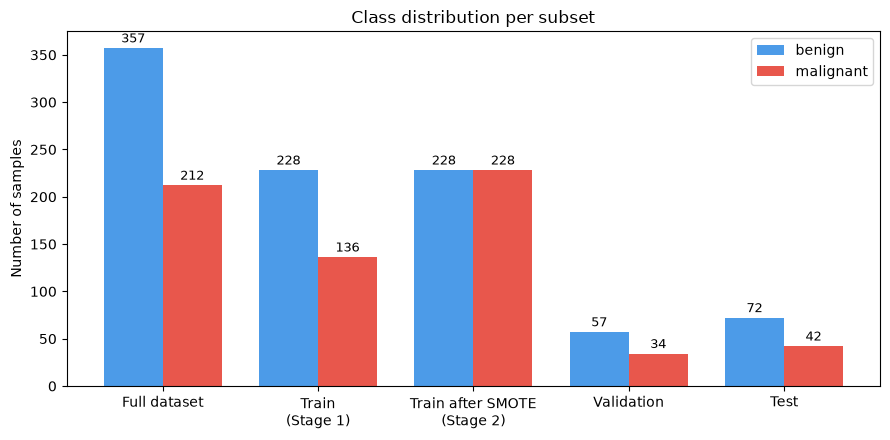

In [6]:
fig = plots.plot_class_distribution(
    {name: {"benign": int(r.benign), "malignant": int(r.malignant)} for name, r in dist.iterrows()},
    FIG_DIR / "class_distribution.png",
)
display(fig)

Check that the scaler really was fitted on training data only: the training
split is exactly zero-mean / unit-variance, while validation and test (scaled
with the *training* statistics) are only approximately so.

In [7]:
for name, Xs in [("train", data.scaled.X_train), ("validation", data.scaled.X_val), ("test", data.scaled.X_test)]:
    print(f"{name:>10}: mean of feature means = {Xs.mean(axis=0).mean():+.4f}, "
          f"mean of feature stds = {Xs.std(axis=0).mean():.4f}")

     train: mean of feature means = +0.0000, mean of feature stds = 1.0000
validation: mean of feature means = -0.0007, mean of feature stds = 0.9738
      test: mean of feature means = -0.0255, mean of feature stds = 0.9159


## 4. Stage 1: original data

Both models are trained by the **same training loop** (`bcd.training.trainer`):
Adam (lr = 0.001), batch size 32, `BCEWithLogitsLoss`, up to 500 epochs with
early stopping on validation loss (patience 30, best weights restored).
The seed is reset before each run.

- **Logistic regression**: `nn.Linear(30, 1)`, no weight decay.
- **ANN**: 30 -> 16 -> 8 -> 1 with ReLU and Dropout(0.2), weight decay 1e-4.

In [8]:
runs = {}
for model_name in MODELS:
    runs[(model_name, STAGE_1)] = exp.train_and_evaluate(model_name, STAGE_1, data, cfg)
    h = runs[(model_name, STAGE_1)].history
    print(f"{model_name:<20} stopped after {h.epochs_run} epochs, best epoch = {h.best_epoch}")

Logistic Regression  stopped after 334 epochs, best epoch = 304


ANN                  stopped after 78 epochs, best epoch = 48


Train and test metrics for Stage 1 (positive class = malignant). Train metrics
are computed on the training split, test metrics on the untouched test set.

In [9]:
METRIC_COLS = ["accuracy", "precision", "recall", "f1", "roc_auc", "tn", "fp", "fn", "tp"]

def stage_table(stage):
    rows = []
    for m in MODELS:
        r = runs[(m, stage)]
        for split, met in (("train", r.train_metrics), ("test", r.test_metrics)):
            rows.append({"model": m, "split": split, **{k: met[k] for k in METRIC_COLS}})
    return pd.DataFrame(rows).set_index(["model", "split"])

display(stage_table(STAGE_1))

accuracy  precision  recall     f1  roc_auc   tn  fp  fn   tp
model               split                                                               
Logistic Regression train    0.9835     0.9851  0.9706 0.9778   0.9971  226   2   4  132
                    test     0.9737     0.9756  0.9524 0.9639   0.9967   71   1   2   40
ANN                 train    0.9863     0.9852  0.9779 0.9815   0.9975  226   2   3  133
                    test     0.9737     0.9756  0.9524 0.9639   0.9974   71   1   2   40

Full classification reports on the test set (per class precision, recall and F1).

In [10]:
for m in MODELS:
    print(f"=== {m} | {STAGE_1} | TEST ===")
    print(runs[(m, STAGE_1)].test_metrics["report"])

=== Logistic Regression | Stage 1 (original) | TEST ===
              precision    recall  f1-score   support

      benign     0.9726    0.9861    0.9793        72
   malignant     0.9756    0.9524    0.9639        42

    accuracy                         0.9737       114
   macro avg     0.9741    0.9692    0.9716       114
weighted avg     0.9737    0.9737    0.9736       114

=== ANN | Stage 1 (original) | TEST ===
              precision    recall  f1-score   support

      benign     0.9726    0.9861    0.9793        72
   malignant     0.9756    0.9524    0.9639        42

    accuracy                         0.9737       114
   macro avg     0.9741    0.9692    0.9716       114
weighted avg     0.9737    0.9737    0.9736       114



Confusion matrices on the test set. Rows are the true class, columns the
predicted class. The bottom-left cell is the **false negatives** (missed
cancers); the top-right cell is the **false positives** (false alarms).

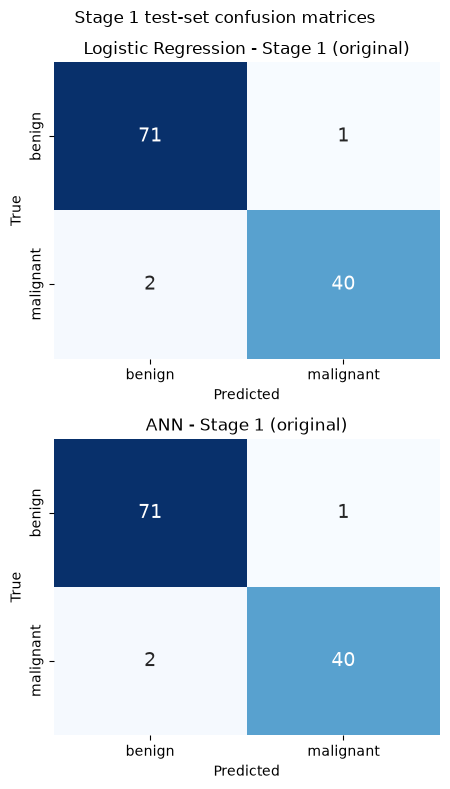

In [11]:
display(plots.plot_confusion_matrices(
    {k: r.test_metrics["confusion_matrix"] for k, r in runs.items()},
    MODELS, [STAGE_1], FIG_DIR / "confusion_matrices_stage1.png",
    title="Stage 1 test-set confusion matrices"))

Learning curves: training and validation loss after every epoch (both
measured in eval mode, so they are directly comparable). The dotted line
marks the epoch whose weights were restored.

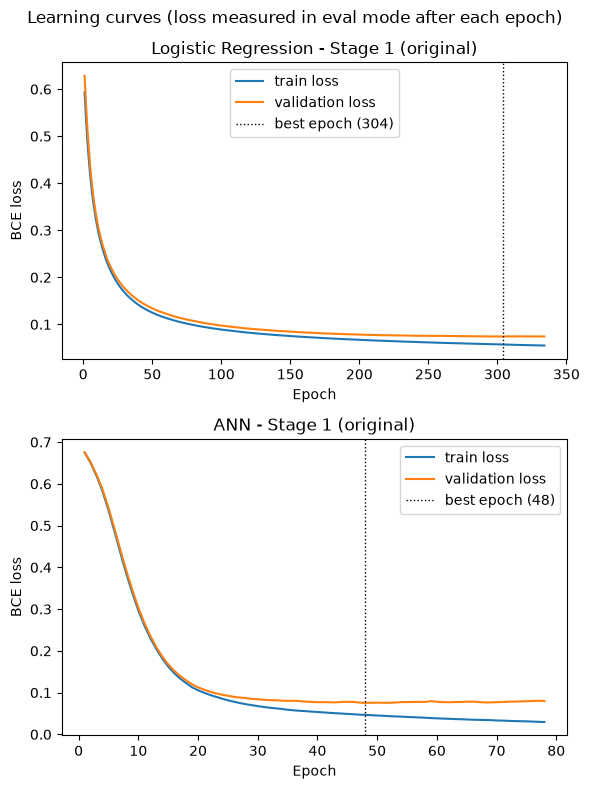

In [12]:
display(plots.plot_loss_curves({k: r.history for k, r in runs.items()},
                               MODELS, [STAGE_1], FIG_DIR / "loss_curves_stage1.png"))

## 5. Stage 2: SMOTE-rebalanced training data

The only change from Stage 1 is the training set: the scaled training split is
oversampled with **SMOTE** (k = 5 neighbours, 1:1 ratio). Each synthetic
malignant sample lies on the line segment between a real malignant sample and
one of its 5 nearest malignant neighbours. The split, scaler, validation and
test sets, architectures, hyperparameters and seed are all unchanged.

In [13]:
before, after = class_counts(data.scaled.y_train), class_counts(data.y_train_smote)
print("Training split before SMOTE:", before, "| total", sum(before.values()))
print("Training split after SMOTE: ", after, "| total", sum(after.values()))
print("Synthetic malignant samples added:", after["malignant"] - before["malignant"])
print("Validation (unchanged):", class_counts(data.scaled.y_val))
print("Test (unchanged):      ", class_counts(data.scaled.y_test))

Training split before SMOTE: {'benign': 228, 'malignant': 136} | total 364
Training split after SMOTE:  {'benign': 228, 'malignant': 228} | total 456
Synthetic malignant samples added: 92
Validation (unchanged): {'benign': 57, 'malignant': 34}
Test (unchanged):       {'benign': 72, 'malignant': 42}


Train both models on the SMOTE training set with the identical training procedure.

In [14]:
for model_name in MODELS:
    runs[(model_name, STAGE_2)] = exp.train_and_evaluate(model_name, STAGE_2, data, cfg)
    h = runs[(model_name, STAGE_2)].history
    print(f"{model_name:<20} stopped after {h.epochs_run} epochs, best epoch = {h.best_epoch}")

Logistic Regression  stopped after 271 epochs, best epoch = 241


ANN                  stopped after 70 epochs, best epoch = 40


Stage 2 metrics. Train metrics are computed on the **real** training samples
(not the synthetic ones), so the train/test gap stays comparable with Stage 1.

In [15]:
display(stage_table(STAGE_2))

accuracy  precision  recall     f1  roc_auc   tn  fp  fn   tp
model               split                                                               
Logistic Regression train    0.9835     0.9779  0.9779 0.9779   0.9971  225   3   3  133
                    test     0.9825     0.9762  0.9762 0.9762   0.9970   71   1   1   41
ANN                 train    0.9890     0.9853  0.9853 0.9853   0.9969  226   2   2  134
                    test     0.9825     0.9762  0.9762 0.9762   0.9974   71   1   1   41

In [16]:
for m in MODELS:
    print(f"=== {m} | {STAGE_2} | TEST ===")
    print(runs[(m, STAGE_2)].test_metrics["report"])

=== Logistic Regression | Stage 2 (SMOTE) | TEST ===
              precision    recall  f1-score   support

      benign     0.9861    0.9861    0.9861        72
   malignant     0.9762    0.9762    0.9762        42

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114

=== ANN | Stage 2 (SMOTE) | TEST ===
              precision    recall  f1-score   support

      benign     0.9861    0.9861    0.9861        72
   malignant     0.9762    0.9762    0.9762        42

    accuracy                         0.9825       114
   macro avg     0.9812    0.9812    0.9812       114
weighted avg     0.9825    0.9825    0.9825       114



Stage 2 confusion matrices on the same test set.

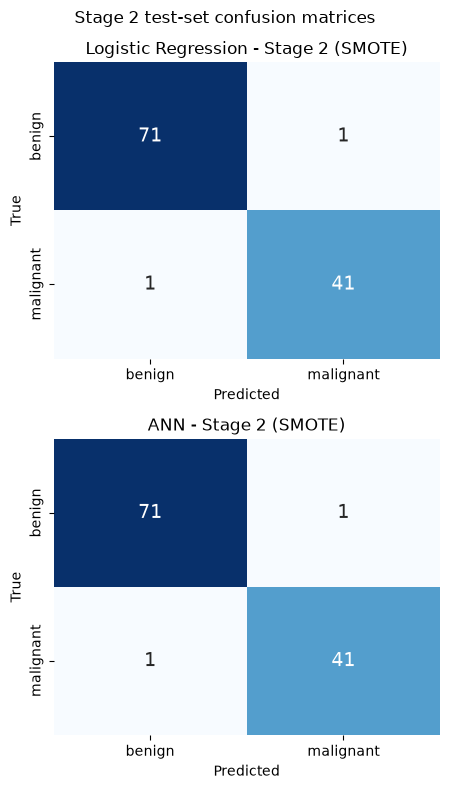

In [17]:
display(plots.plot_confusion_matrices(
    {k: r.test_metrics["confusion_matrix"] for k, r in runs.items()},
    MODELS, [STAGE_2], FIG_DIR / "confusion_matrices_stage2.png",
    title="Stage 2 test-set confusion matrices"))

Stage 2 learning curves. Here the training loss is measured on the SMOTE
training set (the data the model is fitted on); validation is unchanged.

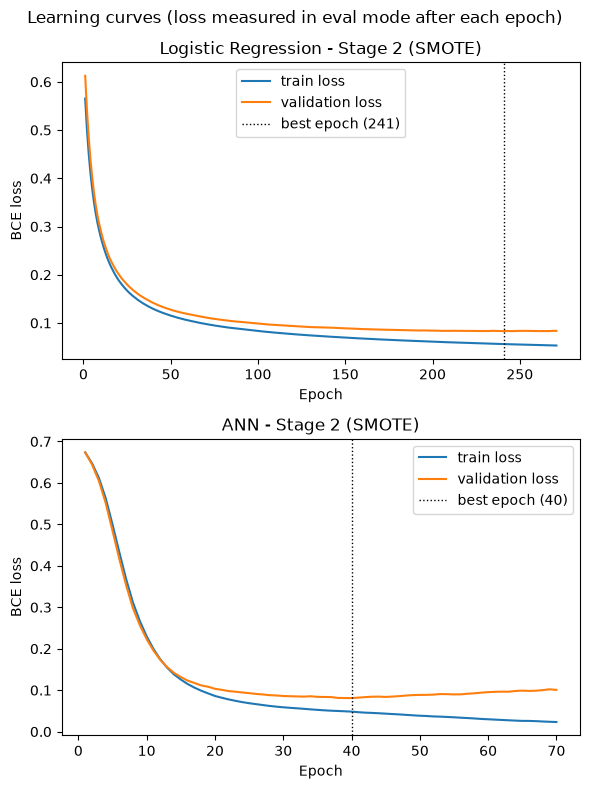

In [18]:
display(plots.plot_loss_curves({k: r.history for k, r in runs.items()},
                               MODELS, [STAGE_2], FIG_DIR / "loss_curves_stage2.png"))

## 6. Comparison

Collect the four runs, save every table to `outputs/results/` and every figure
to `outputs/figures/`.

In [19]:
results = exp.ExperimentResults(data, runs)
paths = exp.save_tables(results, RES_DIR, cfg.training.threshold)
figs = exp.make_figures(results, FIG_DIR)
for name, p in paths.items():
    print(f"{name:<24} -> {p.relative_to(RES_DIR.parents[1])}")

all_metrics              -> outputs\results\all_metrics.csv
stage_comparison         -> outputs\results\stage_comparison.csv
generalisation_gap       -> outputs\results\generalisation_gap.csv
training_summary         -> outputs\results\training_summary.csv
class_distribution       -> outputs\results\class_distribution.csv
misclassified_test_patients -> outputs\results\misclassified_test_patients.csv
classification_reports   -> outputs\results\classification_reports.txt


**Stage 1 vs Stage 2 on the test set.** `delta` = Stage 2 minus Stage 1.
`fn` and `fp` are counts of missed cancers and false alarms (out of the test
set's malignant and benign cases respectively).

In [20]:
comparison = exp.comparison_table(results)
display(comparison.set_index(["model", "metric"]))

Stage 1 (original)  Stage 2 (SMOTE)   delta
model               metric                                                
Logistic Regression accuracy               0.9737           0.9825  0.0088
                    precision              0.9756           0.9762  0.0006
                    recall                 0.9524           0.9762  0.0238
                    f1                     0.9639           0.9762  0.0123
                    roc_auc                0.9967           0.9970  0.0003
                    fn                     2.0000           1.0000 -1.0000
                    fp                     1.0000           1.0000  0.0000
ANN                 accuracy               0.9737           0.9825  0.0088
                    precision              0.9756           0.9762  0.0006
                    recall                 0.9524           0.9762  0.0238
                    f1                     0.9639           0.9762  0.0123
                    roc_auc                0.9974           0.9974  0.0000
                    fn                     2.0000           1.0000 -1.0000
                    fp                     1.0000           1.0000  0.0000

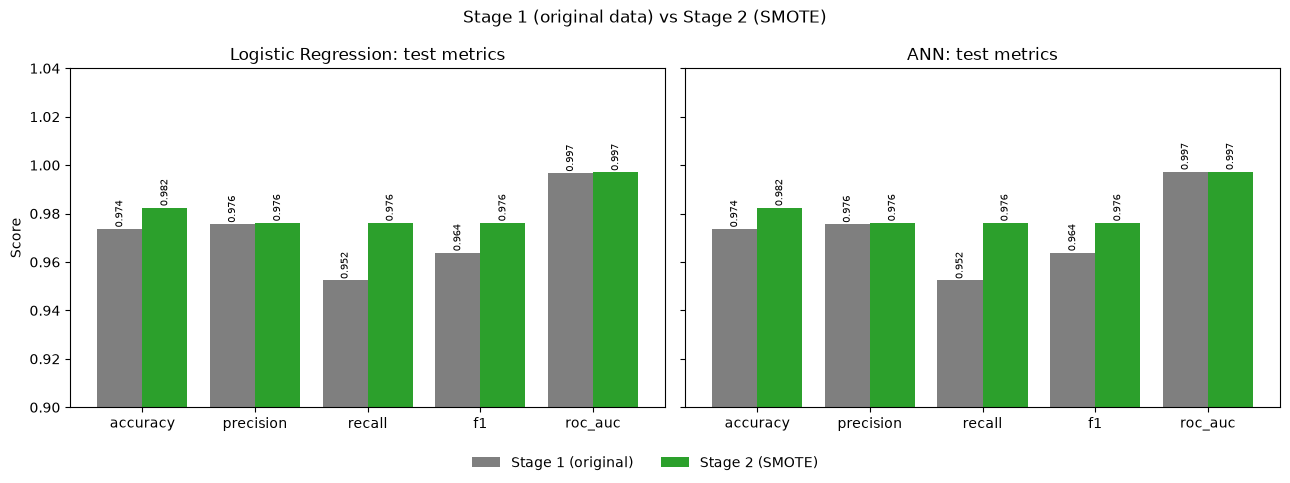

In [21]:
display(figs['stage_comparison'])

ROC curves on the test set. The closer a curve is to the top-left corner,
the better the model ranks malignant cases above benign ones regardless of
the threshold.

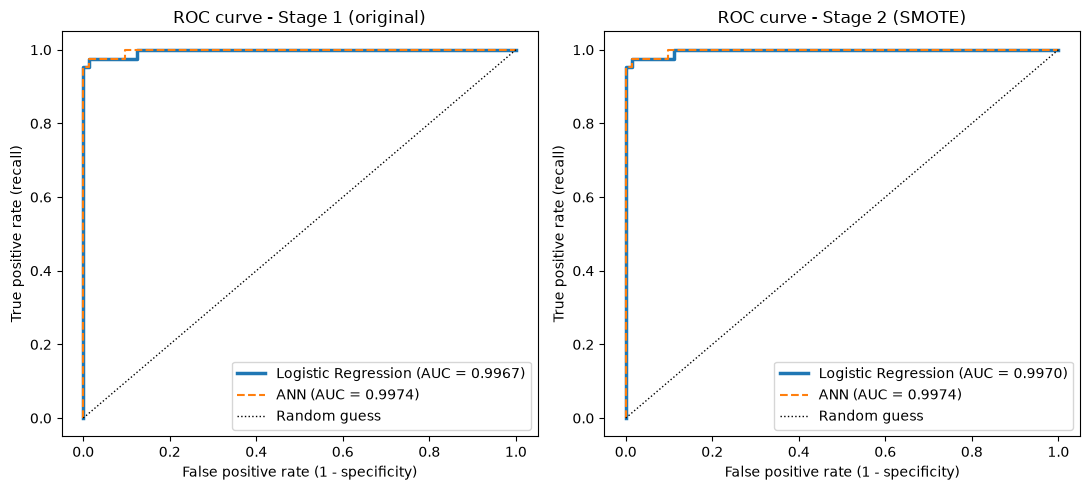

In [22]:
display(figs['roc_curves'])

All four test-set confusion matrices side by side.

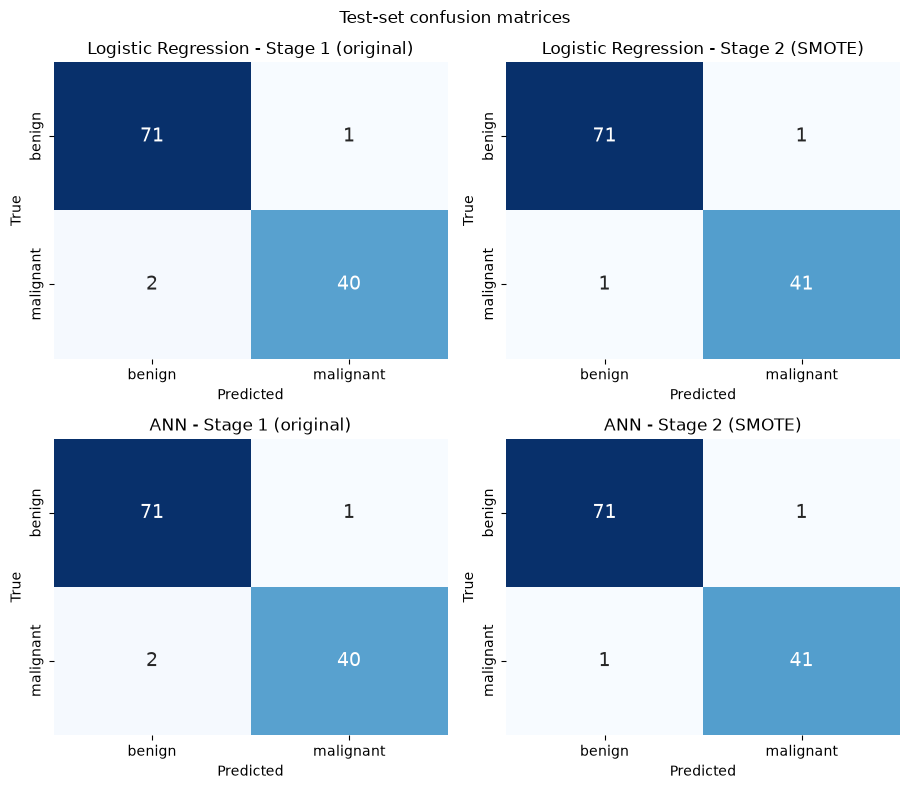

In [23]:
display(figs['confusion_matrices'])

**Which patients are misclassified?** Every test patient that at least one
run gets wrong, with P(malignant) from each run (>= 0.5 means "predicted
malignant"). This traces the metric changes back to individual cases.

In [24]:
display(exp.misclassified_table(results, cfg.training.threshold).round(3))

,true_class,Logistic Regression | Stage 1 (original),ANN | Stage 1 (original),Logistic Regression | Stage 2 (SMOTE),ANN | Stage 2 (SMOTE)
test_index,,,,,
4,benign,0.5500,0.6030,0.6420,0.7280
16,malignant,0.0720,0.0320,0.0970,0.0390
112,malignant,0.4490,0.4580,0.5650,0.7100


**Generalisation gap** (train minus test) for every model and stage. A large
positive gap means the model does much better on data it was fitted on than
on unseen patients, i.e. overfitting.

In [25]:
gap = exp.generalisation_gap_table(results)
display(gap.pivot_table(index=["model", "stage"], columns="metric", values="gap", sort=False)
           [["accuracy", "precision", "recall", "f1", "roc_auc"]])
display(exp.training_summary_table(results).set_index(["model", "stage"]))

metric                                  accuracy  precision  recall     f1  roc_auc
model               stage                                                          
Logistic Regression Stage 1 (original)    0.0098     0.0095  0.0182 0.0139   0.0004
                    Stage 2 (SMOTE)       0.0011     0.0018  0.0018 0.0018   0.0000
ANN                 Stage 1 (original)    0.0126     0.0096  0.0256 0.0177   0.0001
                    Stage 2 (SMOTE)       0.0066     0.0091  0.0091 0.0091  -0.0005

,,n_train_samples,epochs_run,best_epoch,train_loss_at_best,val_loss_at_best
model,stage,,,,,
Logistic Regression,Stage 1 (original),364,334,304,0.0571,0.0743
ANN,Stage 1 (original),364,78,48,0.0467,0.0754
Logistic Regression,Stage 2 (SMOTE),456,271,241,0.0562,0.0831
ANN,Stage 2 (SMOTE),456,70,40,0.0483,0.0810


All four learning curves together.

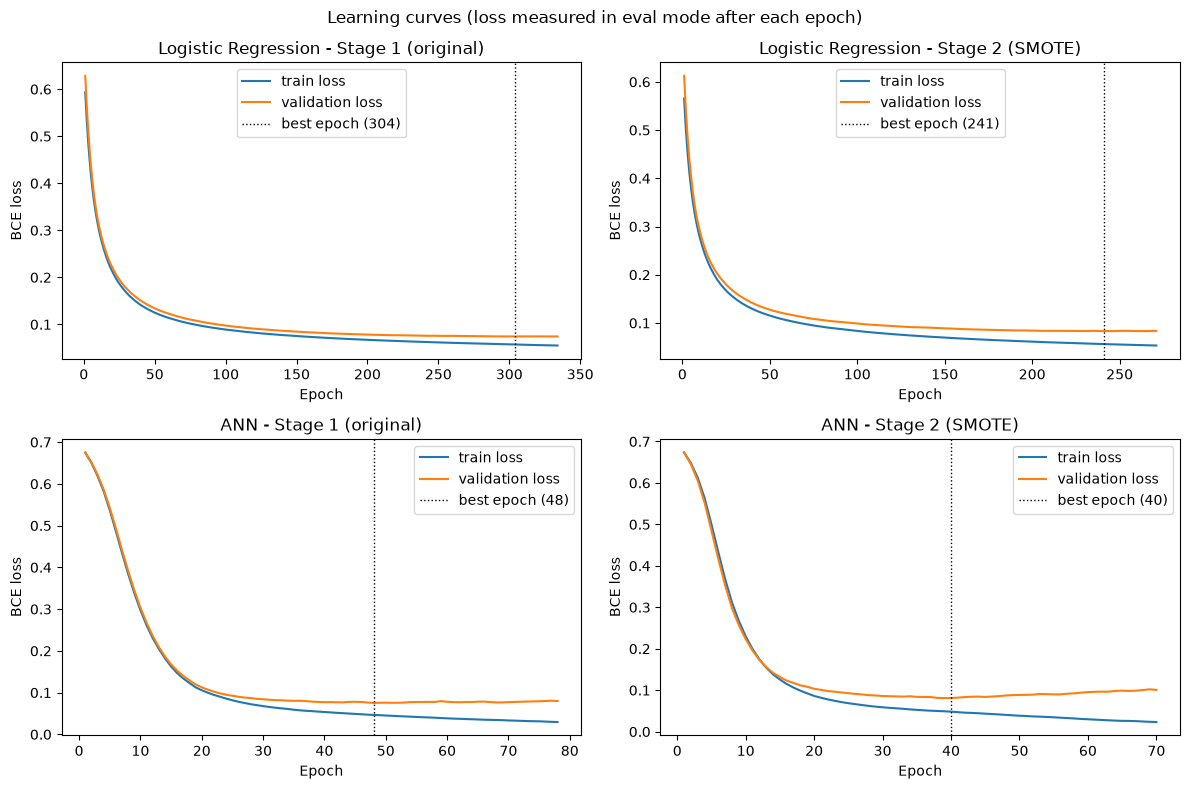

In [26]:
display(figs['loss_curves'])

### Optional checks (not part of the main results)

**Sanity check.** scikit-learn's `LogisticRegression` (L-BFGS, default mild
L2 penalty, run to convergence) on exactly the same scaled data, compared with
our PyTorch logistic regression on the test set. `agreement` is the share of
test patients both implementations label identically.

In [27]:
sanity = optional_checks.sklearn_sanity_check(results, cfg)
sanity.to_csv(RES_DIR / "optional_sklearn_sanity_check.csv", index=False, float_format="%.6f")
display(sanity.set_index(["implementation", "stage"]))

,,accuracy,precision,recall,f1,roc_auc,fn,fp,agreement
implementation,stage,,,,,,,,
PyTorch LR,Stage 1 (original),0.9737,0.9756,0.9524,0.9639,0.9967,2,1,0.9912
scikit-learn LR,Stage 1 (original),0.9825,0.9762,0.9762,0.9762,0.9960,1,1,0.9912
PyTorch LR,Stage 2 (SMOTE),0.9825,0.9762,0.9762,0.9762,0.9970,1,1,0.9912
scikit-learn LR,Stage 2 (SMOTE),0.9737,0.9535,0.9762,0.9647,0.9954,1,2,0.9912


**Stability check.** Stratified 5-fold cross-validation on the training split
(364 samples). For each fold the scaler, SMOTE and the model are refitted on
the fold's training part; early stopping uses the fixed validation split; the
held-out fold is only scored. The test set is not touched. The standard
deviation shows how much a metric moves with a different subset of patients.

In [28]:
cv = optional_checks.cross_validation_check(results, cfg)
cv_summary = optional_checks.summarise_cv(cv)
cv.to_csv(RES_DIR / "optional_cv_folds.csv", index=False, float_format="%.6f")
cv_summary.to_csv(RES_DIR / "optional_cv_summary.csv", float_format="%.6f")
display(cv_summary[[c for c in cv_summary.columns if c.startswith(("recall", "f1", "roc_auc", "accuracy"))]])

,,accuracy_mean,accuracy_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
model,stage,,,,,,,,
Logistic Regression,Stage 1 (original),0.9780,0.0208,0.9632,0.0262,0.9704,0.0281,0.9942,0.0073
ANN,Stage 1 (original),0.9726,0.0274,0.9632,0.0454,0.9630,0.0377,0.9928,0.0099
Logistic Regression,Stage 2 (SMOTE),0.9670,0.0229,0.9558,0.0406,0.9555,0.0317,0.9939,0.0071
ANN,Stage 2 (SMOTE),0.9726,0.0274,0.9632,0.0454,0.9630,0.0377,0.9928,0.0099


Per-fold results. Note that the ANN's fold scores coincide in Stage 1 and
Stage 2. The two ANNs are different models (different training data,
different stopping epochs, and different test-set predictions above), but on
each held-out fold they get the same few borderline patients wrong, so the
scores coincide. This is another sign that the remaining errors come from a
handful of hard cases rather than from the class balance.

In [29]:
display(cv.pivot_table(index=['model', 'stage'], columns='fold', values='recall', sort=False).round(4))

fold                                        1      2      3      4      5
model               stage                                                
Logistic Regression Stage 1 (original) 0.9630 1.0000 0.9259 0.9643 0.9630
                    Stage 2 (SMOTE)    0.9630 1.0000 0.8889 0.9643 0.9630
ANN                 Stage 1 (original) 0.9630 1.0000 0.8889 0.9643 1.0000
                    Stage 2 (SMOTE)    0.9630 1.0000 0.8889 0.9643 1.0000

## 7. Answers to the questions

The key test-set numbers the answers rely on, in one place:

In [30]:
key = exp.metrics_table(results)
display(key.set_index(["model", "stage", "split"])[["accuracy", "precision", "recall", "f1", "roc_auc", "fn", "fp"]])

accuracy  precision  recall     f1  roc_auc  fn  fp
model               stage              split                                                     
Logistic Regression Stage 1 (original) train    0.9835     0.9851  0.9706 0.9778   0.9971   4   2
                                       test     0.9737     0.9756  0.9524 0.9639   0.9967   2   1
ANN                 Stage 1 (original) train    0.9863     0.9852  0.9779 0.9815   0.9975   3   2
                                       test     0.9737     0.9756  0.9524 0.9639   0.9974   2   1
Logistic Regression Stage 2 (SMOTE)    train    0.9835     0.9779  0.9779 0.9779   0.9971   3   3
                                       test     0.9825     0.9762  0.9762 0.9762   0.9970   1   1
ANN                 Stage 2 (SMOTE)    train    0.9890     0.9853  0.9853 0.9853   0.9969   2   2
                                       test     0.9825     0.9762  0.9762 0.9762   0.9974   1   1

### Q1 (Stage 1). Is accuracy alone a sufficient metric here, and which of precision, recall, F1 and ROC-AUC matter most?

**No, accuracy alone is not sufficient.**

- **Accuracy hides the errors that matter.** The test set has 72 benign and
  42 malignant patients. A "model" that always answers *benign* would already
  reach 72/114 = 63.2% accuracy while catching **zero** cancers. Our Stage 1
  models reach 97.37% test accuracy, and that single number does not show
  that **2 of the 42 cancers were missed**. Accuracy weighs a missed cancer
  and a false alarm equally, but clinically they are not equal.
- **Recall (malignant) matters most.** It is the share of real cancers
  that are detected: 40/42 = **0.9524** for both models in Stage 1. Every
  point of recall lost is a missed cancer.
- **Precision is the price paid in false alarms.** It is the share of
  "malignant" predictions that are correct: 40/41 = **0.9756**. A low value
  would mean many unnecessary follow-up examinations.
- **F1** (0.9639) summarises both in one number and is only high when
  precision and recall are both high. That makes it useful for comparing
  models when one wins on recall and the other on precision.
- **ROC-AUC** (0.9967 for LR, 0.9974 for the ANN) does not depend on the 0.5
  threshold. It measures how well the model *ranks* malignant above benign
  cases. A value this close to 1 means the classes are almost perfectly
  separable by the predicted score, and the remaining errors are a question
  of where the threshold sits for a few borderline patients.

**Ranking for this diagnosis:** recall first, then F1 and ROC-AUC, with
precision reported to keep the false-alarm cost visible.

### Q2 (Stage 1). What does the confusion matrix show about false negatives versus false positives?

Both Stage 1 confusion matrices (on the test set) are identical:

| | predicted benign | predicted malignant |
|---|---|---|
| **true benign (72)** | TN = 71 | **FP = 1** |
| **true malignant (42)** | **FN = 2** | TP = 40 |

- **False negatives outnumber false positives (2 vs 1), and the gap is
  larger as a rate.** 2 of 42 malignant cases are missed (4.8%), but only
  1 of 72 benign cases is falsely flagged (1.4%). The models make
  proportionally **more than three times as many errors on the malignant
  class**, which is the opposite of what the clinical costs call for.
- **Why this happens:** the loss treats every sample equally and the
  training data has 228 benign vs 136 malignant cases, so the fitted
  decision boundary leans towards the majority (benign) class.
- **The misclassified-patients table shows that the two missed cancers are
  different kinds of error.** Patient 112 is borderline: P(malignant) =
  0.449 (LR) and 0.458 (ANN), just under the 0.5 threshold. Patient 16 is
  confidently wrong (P = 0.072 / 0.032): its measurements look benign to
  both models. The false alarm (patient 4) is also borderline (0.550 / 0.603).

This imbalance between FN and FP motivates Stage 2.

### Q3 (Stage 1). How does the logistic regression baseline compare with the ANN?

**On the test set they are practically the same model.**

- **Same predictions.** Both make the same predictions on every one of the
  114 test patients. They get the same three patients wrong (16, 112, 4), so
  all threshold-based metrics are identical: accuracy 0.9737, precision
  0.9756, recall 0.9524, F1 0.9639.
- **Slightly better ranking for the ANN.** ROC-AUC is 0.9974 vs 0.9967.
  With 42 × 72 = 3024 malignant/benign pairs, that is 8 vs 10 misordered
  pairs. This difference is too small to matter.
- **Faster convergence, much bigger model.** The ANN reached its best
  validation loss at epoch 48, against epoch 304 for LR. It has 641
  parameters against 31.
- **The optional 5-fold CV agrees.** LR recall is 0.963 ± 0.026 and ANN
  recall 0.963 ± 0.045. LR F1 is 0.970 ± 0.028 and ANN F1 0.963 ± 0.038.
  The means are equal within noise, and the ANN varies more from fold to fold.

**Interpretation.** The classes are almost linearly separable in the
standardised feature space (ROC-AUC ≈ 0.997 for a linear model), so the
ANN's ability to learn non-linear boundaries has nothing left to gain.
Given equal performance, **logistic regression is preferable** here: it is
simpler, faster to train, less variable, and its 30 weights can be
inspected directly.

### Q4 (Stage 1). Is either model overfitting?

**Neither final model is overfitting, and neither underfits.** The evidence
comes from two sources.

**1. Train vs test gap (generalisation-gap table):**

| Stage 1 | train accuracy | test accuracy | train recall | test recall | train AUC | test AUC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.9835 | 0.9737 | 0.9706 | 0.9524 | 0.9971 | 0.9967 |
| ANN | 0.9863 | 0.9737 | 0.9779 | 0.9524 | 0.9975 | 0.9974 |

The gaps are small: about 1 percentage point in accuracy, 1.8 (LR) and 2.6
(ANN) points in recall, and below 0.0005 in ROC-AUC. On a test set with 42
malignant cases, one patient is worth 2.4 recall points, so the recall gap
amounts to about one patient. Both train and test scores are high, so there
is no underfitting either.

**2. Learning curves (Stage 1 loss curves):**
- **Logistic regression: good fit.** Training and validation loss fall
  together and level off with a small, stable gap (0.057 vs 0.074 at the
  best epoch). Validation loss flattens out at the end and does not rise.
- **ANN: good fit at the restored weights, with the onset of overfitting
  after that.** Validation loss reaches its minimum (0.075) at epoch 48 and
  then stays flat or slightly rises, while training loss keeps falling, to
  about 0.03 by epoch 78. That widening gap is the classic sign that the
  network has started to fit the training data more closely than it
  generalises. **Early stopping caught it** and restored the epoch-48
  weights, and together with the small size, dropout and weight decay, this
  keeps the final ANN from overfitting.

### Q5 (Stage 2). How did you rebalance or augment the data?

With **SMOTE** (Synthetic Minority Over-sampling Technique) from
imbalanced-learn, using `k_neighbors=5`, a 1:1 target ratio and
`random_state=42`:

- **How it works.** For each new sample, SMOTE takes a real malignant
  training sample and one of its 5 nearest malignant neighbours, and creates
  a synthetic point at a random position on the line segment between them.
- **What changed.** The malignant class in the training split grew from 136
  to 228 (**92 synthetic samples**), matching the 228 benign cases. The
  training set went from 364 to 456 samples.
- **What did not change.** Validation (57 benign / 34 malignant) and test
  (72 / 42) are untouched, so early stopping and evaluation still reflect the
  real class mix. The split, scaler, architectures, hyperparameters and seed
  are identical to Stage 1; SMOTE is the only difference.
- **Order of operations.** SMOTE runs **after** the split, so no synthetic
  point is ever built from a test patient (no leakage). It also runs
  **after** scaling, because its nearest-neighbour search uses Euclidean
  distance, which raw features would distort (area is in the hundreds,
  smoothness around 0.1).
- **Why SMOTE.** Random oversampling only duplicates rows and invites
  memorisation. Class weights change the loss rather than the data, while
  the brief asks for data augmentation. Undersampling would discard real
  patients from an already small dataset.

### Q6 (Stage 2). Did augmentation change minority-class recall and the other metrics, and did it help overall?

**Yes, minority-class recall improved, by exactly one patient, and on the
test set nothing got worse.** Both models change in the same way:

| Test set | Stage 1 | Stage 2 (SMOTE) | change |
|---|---|---|---|
| recall (malignant) | 0.9524 (40/42) | **0.9762 (41/42)** | +0.0238 |
| missed cancers (FN) | 2 | **1** | −1 |
| false alarms (FP) | 1 | 1 | 0 |
| precision | 0.9756 | 0.9762 | +0.0006 |
| F1 | 0.9639 | 0.9762 | +0.0123 |
| accuracy | 0.9737 | 0.9825 | +0.0088 |
| ROC-AUC (LR / ANN) | 0.9967 / 0.9974 | 0.9970 / 0.9974 | +0.0003 / 0.0000 |

**What SMOTE actually did** (from the misclassified-patients table):

- **Borderline cancer now caught.** Patient 112 moved from P = 0.449 / 0.458
  to 0.565 / 0.710, above the threshold.
- **Hard case still missed.** Patient 16 stays missed (P = 0.097 / 0.039).
  Its measurements look benign, and rebalancing cannot fix that.
- **The false alarm became more confident.** Patient 4 went from 0.550 /
  0.603 to 0.642 / 0.728.
- **Same ranking, shifted probabilities.** ROC-AUC is essentially
  unchanged, so the models did not get better at separating the classes.
  Training on a 50/50 class mix instead pushed predicted probabilities
  towards *malignant*, moving the 0.5 decision point in the direction that
  favours recall. That is the direction the clinical costs call for.
- **Side effect on the curves.** Stage 2 validation loss at the best epoch
  is slightly higher (0.083 / 0.081 vs 0.074 / 0.075). The validation set
  keeps the real 37% malignant share, and probabilities tuned to a 50/50 mix
  are a little less well calibrated for it. The ANN's validation loss also
  rises more clearly after its best epoch (epoch 40), so early stopping
  mattered even more.
- **Overfitting did not get worse.** The train/test gaps became smaller,
  e.g. accuracy 0.9835 vs 0.9825 for LR.

**Did it help overall?** Yes, but modestly, and the evidence is weak:
- **For:** on the test set, one more cancer was caught at no cost in false
  alarms, and F1 and accuracy improved for both models.
- **Against:** the gain is a single patient, and one patient is worth 2.4
  recall points on this test set. The optional 5-fold CV on the training
  split shows **no consistent improvement**. LR recall went from 0.963 to
  0.956, and the ANN stayed at 0.963, with fold-to-fold standard deviations
  of 0.03–0.05.

The imbalance here is mild (37% / 63%) and the classes are well separated,
so there was little for rebalancing to fix. SMOTE is a reasonable,
low-risk choice that moves the models in the clinically right direction,
but it is not a decisive improvement on this dataset.

## 8. Reflection

**What worked.**
- **Strong models.** Both reach about 97–98% test accuracy and ROC-AUC
  ≈ 0.997 on unseen patients.
- **No leakage.** The split comes first, the scaler is fitted on train only,
  and SMOTE is applied to train only, so the test set really is unseen. The
  tests check each of these properties.
- **Generalisation under control.** The learning curves and the small
  train/test gaps show good generalisation. Early stopping visibly
  prevented the ANN from overfitting.
- **Fair comparisons.** Both models share one training loop, one split and
  one threshold, so the LR-vs-ANN and Stage 1-vs-Stage 2 comparisons
  isolate one factor at a time.

**What the results taught us.**
- **Model complexity has to be justified by the data.** On a small,
  almost linearly separable dataset, the ANN brings no measurable benefit
  over logistic regression.
- **Accuracy is the wrong lens.** Every model looks excellent by accuracy,
  and only the confusion matrix and recall show the missed cancers.
- **Small test sets make small differences uncertain.** With 42 malignant
  test cases, one patient moves recall by 2.4 points. The k-fold check is
  what showed that SMOTE's test-set gain is within normal variation.

**Limitations.**
- **One small test set (114 patients).** Every reported number has
  noticeable uncertainty.
- **Fixed 0.5 threshold.** This is deliberate, to keep the comparison
  fair. In practice the threshold is the most direct lever for trading
  false alarms against missed cancers.
- **Synthetic samples.** SMOTE points are interpolations, not real
  patients. With strongly correlated features (radius, perimeter, area),
  some may be less realistic than they look.
- **Persistent hard cases.** One malignant patient (test patient 16) is
  confidently classified as benign by every model. No rebalancing fixes
  that, because its measurements resemble benign cases.

**What I would do next.**
- **Choose the threshold on the validation set** to meet a target recall,
  for example ≥ 0.98, never on the test set, and report the resulting
  false-alarm rate.
- **Compare SMOTE with class weighting** (`pos_weight`) and report both
  with repeated cross-validation, so differences of one patient can be
  judged statistically.
- **Validate on data from another hospital or scanner** before any
  clinical use. A model like this should support case prioritisation, with
  a human reviewing every case, not replace diagnosis.